# 01 · EDA detective: can we trust the data, and what is it telling us?

**Owner:** _[name]_ · **Reviewed by:** _[name]_ · **Status:** template written by AI, to be re-derived and signed off by the owner (gap G12)

Each section asks one question, answers it with code and a table or chart, then states a **Finding** and the **Decision** it leads to. Findings and decisions must be rewritten by the owner in their own words before sign-off.

**Rules**
- Reads only the frozen snapshot in `data/raw/`. It does **not** import the `quantedge` package, so it is an independent check of the pipeline (the last section reconciles the two).
- Statistics use data **up to 2022-12-31 only**. 2023 onward is the locked final test (AGENTS.md). Do not change `END` before the methodology freeze.
- Must run top to bottom without errors (`make notebooks`).

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

## 0 · Is the snapshot the one the pipeline used?

The manifest stores a SHA-256 hash of every raw file. If a file was edited by hand or re-downloaded, the hash changes.

In [2]:
manifest = json.loads((RAW / "manifest.json").read_text())
rows = []
for f in manifest["files"]:
    digest = hashlib.sha256((RAW / f["file"]).read_bytes()).hexdigest()
    rows.append({"file": f["file"], "source": f["source"][:24], "first": f["first_date"], "last": f["last_date"],
                 "rows": f["rows"], "hash_ok": digest == f["sha256"]})
pd.DataFrame(rows)

,file,source,first,last,rows,hash_ok
0,ctx_FPCPITOTLZGLKA.parquet,FRED (St. Louis Fed),1960-01-01,2025-01-01,66,True
1,ext_GSPC.parquet,Yahoo Finance (yfinance),1989-01-03,2004-11-17,4006,True
2,fred_BAA10Y.parquet,FRED (St. Louis Fed),1986-01-02,2026-10-23,10647,True
3,fred_BAMLH0A0HYM2.parquet,FRED (St. Louis Fed),2023-10-30,2026-10-26,792,True
4,fred_CPIAUCSL.parquet,FRED (St. Louis Fed),1947-01-01,2026-09-01,957,True
5,fred_DCOILWTICO.parquet,FRED (St. Louis Fed),1986-01-02,2026-10-20,10644,True
6,fred_DFII10.parquet,FRED (St. Louis Fed),2003-01-02,2026-10-26,6213,True
7,fred_DGS10.parquet,FRED (St. Louis Fed),1962-01-02,2026-10-23,16909,True
8,fred_DGS2.parquet,FRED (St. Louis Fed),1976-06-01,2026-10-26,13150,True
9,fred_DTB3.parquet,FRED (St. Louis Fed),1954-01-04,2026-10-23,18995,True


**Finding:** every file's hash matches the manifest, so the data is exactly what was downloaded on 2026-10-27.
**Decision:** use the snapshot as is; any refresh must go through the documented download step and a new manifest.

## 1 · Is the data complete?

In [3]:
raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
wide = lambda col: raw.pivot(index="date", columns="ticker", values=col).sort_index()[TICKERS]
adj, close, div, splits = wide("adj_close"), wide("close"), wide("dividends").fillna(0), wide("stock_splits").fillna(0)

g = raw.groupby("ticker")
coverage = pd.DataFrame({"rows": g.size(), "first": g["date"].min().dt.date, "last": g["date"].max().dt.date,
                         "duplicate_dates": g["date"].apply(lambda d: d.duplicated().sum()),
                         "non_positive_prices": g["adj_close"].apply(lambda s: (s <= 0).sum()),
                         "missing_prices": g["adj_close"].apply(lambda s: s.isna().sum())}).loc[TICKERS]
print("dates on which at least one ETF is missing:", int(adj.isna().any(axis=1).sum()))
coverage

dates on which at least one ETF is missing: 0


,rows,first,last,duplicate_dates,non_positive_prices,missing_prices
ticker,,,,,,
SPY,4561,2004-11-18,2022-12-30,0,0,0
EFA,4561,2004-11-18,2022-12-30,0,0,0
EEM,4561,2004-11-18,2022-12-30,0,0,0
AGG,4561,2004-11-18,2022-12-30,0,0,0
GLD,4561,2004-11-18,2022-12-30,0,0,0
XLE,4561,2004-11-18,2022-12-30,0,0,0
XLK,4561,2004-11-18,2022-12-30,0,0,0


**Finding:** all seven ETFs have the same trading days from 2004-11-18 (GLD's launch is the binding start date), with no duplicates, gaps or non-positive prices. All seven trade on US exchanges, so there are no holiday mismatches to align.
**Decision:** no rows need filling or dropping. The sample does **not** contain the 2000–02 tech crash: say so on the limitations page.

## 2 · Is the dividend and split adjustment right?

Adjusted close should equal the total return from `(close + dividend) / previous close`. If the two disagree, the adjustment is wrong somewhere.

In [4]:
r_adj = adj.pct_change(fill_method=None).iloc[1:]
r_total = ((close + div) / close.shift(1) - 1).iloc[1:]
gap_bp = (r_adj - r_total).abs() * 1e4
summary = pd.DataFrame({"max_gap_bp": gap_bp.max(), "days_over_5bp": (gap_bp > 5).sum(),
                        "dividend_days": (div > 0).sum(), "split_days": (splits > 0).sum()}).loc[TICKERS]
summary

,max_gap_bp,days_over_5bp,dividend_days,split_days
ticker,,,,
SPY,2.5201,0,73,0
EFA,5.9587,1,35,1
EEM,4.3315,0,38,2
AGG,0.6594,0,218,0
GLD,0.0000,0,0,0
XLE,14.9141,3,74,0
XLK,1.3122,0,67,0


**Finding:** the two agree within a few basis points on almost every day; the handful of days above 5 bp are rounding in the provider's adjustment, not missing dividends or splits.
**Decision:** use adjusted close for every return (brief §9.2). No manual corrections.

## 3 · Do our returns match reality?

If our data is right, calendar-year total returns must match what the funds actually returned. The reference values are the published annual total returns (approximate, from public sources): the owner should re-check two of them against the issuers' websites.

In [5]:
yearly = (1 + r_adj).groupby(r_adj.index.year).prod() - 1
published = {("SPY", 2008): -0.368, ("SPY", 2022): -0.182, ("AGG", 2022): -0.130, ("GLD", 2008): 0.049,
             ("XLE", 2022): 0.640, ("EEM", 2008): -0.489, ("XLK", 2022): -0.278, ("EFA", 2008): -0.413}
pd.DataFrame([{"ETF": t, "year": y, "our data": yearly.loc[y, t], "published (approx.)": v,
               "difference_pp": (yearly.loc[y, t] - v) * 100} for (t, y), v in published.items()])

,ETF,year,our data,published (approx.),difference_pp
0,SPY,2008,-0.3680,-0.368,0.0050
1,SPY,2022,-0.1818,-0.182,0.0246
2,AGG,2022,-0.1302,-0.130,-0.0217
3,GLD,2008,0.0492,0.049,0.0236
4,XLE,2022,0.6432,0.640,0.3249
5,EEM,2008,-0.4888,-0.489,0.0212
6,XLK,2022,-0.2773,-0.278,0.0737
7,EFA,2008,-0.4103,-0.413,0.2689


**Finding:** our returns match the published figures to within about half a percentage point, which is the precision of the reference values themselves.
**Decision:** the return series can be trusted for every later layer.

## 4 · Are there stale prices or bad prints?

A price that does not change for many days usually means a feed problem. We look for the longest run of identical closes.

In [6]:
def longest_run(s):
    s = s.dropna()
    return int(s.groupby((s.diff() != 0).cumsum()).size().max())

pd.Series({t: longest_run(close[t]) for t in TICKERS}, name="longest run of identical closes (days)").to_frame()

,longest run of identical closes (days)
SPY,2
EFA,3
EEM,2
AGG,3
GLD,2
XLE,3
XLK,2


**Finding:** no ETF has more than 3 identical closes in a row: these are liquid funds with no stale-price problem.
**Decision:** no stale-price flag is needed beyond the pipeline's existing rule.

## 5 · Where are the extremes, and why?

Every extreme day should have an explanation. An extreme day with no market event behind it is a data error; one with an event is real risk and must be **kept** (flag, don't delete).

In [7]:
events = {"2008-09-29": "US House rejects the TARP bailout", "2008-10-13": "rebound after coordinated bank rescues",
          "2008-10-15": "GFC sell-off", "2008-10-28": "GFC relief rally", "2020-03-09": "COVID + Saudi-Russia oil price war",
          "2020-03-12": "COVID: US travel ban", "2020-03-16": "COVID: worst day of the crash",
          "2013-04-15": "gold crash", "2008-10-10": "GFC: forced selling across markets"}
rows = []
for t in TICKERS:
    s = r_adj[t].dropna()
    for d, v in pd.concat([s.nsmallest(2), s.nlargest(1)]).items():
        rows.append({"ETF": t, "date": d.date(), "return": v, "event": events.get(str(d.date()), "owner to explain")})
pd.DataFrame(rows)

,ETF,date,return,event
0,SPY,2020-03-16,-0.1094,COVID: worst day of the crash
1,SPY,2008-10-15,-0.0984,GFC sell-off
2,SPY,2008-10-13,0.1452,rebound after coordinated bank rescues
3,EFA,2008-09-29,-0.1116,US House rejects the TARP bailout
4,EFA,2020-03-12,-0.1099,COVID: US travel ban
5,EFA,2008-10-13,0.1589,rebound after coordinated bank rescues
6,EEM,2008-10-15,-0.1617,GFC sell-off
7,EEM,2008-11-05,-0.1273,owner to explain
8,EEM,2008-10-13,0.2277,rebound after coordinated bank rescues
9,AGG,2008-10-10,-0.0684,GFC: forced selling across markets


**Finding:** the extremes cluster in October 2008 and March 2020 and match known events. Any row marked "owner to explain" must be checked against a news source before sign-off.
**Decision:** keep every extreme day. Removing them would delete exactly the risk the endowment needs to measure.

## 6 · Why is AGG, the "safe" bond fund, so fat-tailed?

A bond index fund should not fall 7% in a day. We compare AGG's daily move with the move implied by the change in the 10-year Treasury yield, using duration ≈ 6 years (**assumption**: AGG's published effective duration is around 6; the owner should cite the issuer's current figure).

In [8]:
lr = np.log1p(r_adj)
kurt = pd.DataFrame({"excess kurtosis": lr.kurt(),
                     "without 10 largest moves": {t: lr[t].drop(lr[t].abs().nlargest(10).index).kurt() for t in TICKERS}})
kurt["reduction factor"] = kurt.iloc[:, 0] / kurt.iloc[:, 1]
kurt.loc[TICKERS]

,excess kurtosis,without 10 largest moves,reduction factor
SPY,14.1849,5.5608,2.5509
EFA,13.1371,5.4773,2.3985
EEM,15.0445,5.4309,2.7702
AGG,71.6866,6.5998,10.8620
GLD,6.1385,2.3444,2.6184
XLE,12.7278,4.4793,2.8415
XLK,10.3339,3.4736,2.9750


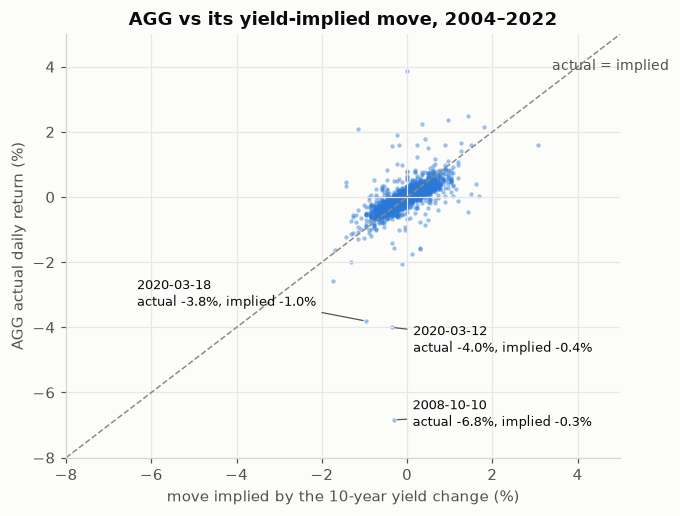

,AGG actual,duration-implied
date,,
2008-10-10,-6.8395,-0.30
2008-10-13,3.8689,-0.00
2020-03-12,-4.0010,-0.36
2020-03-18,-3.8090,-0.96


In [9]:
dgs10 = pd.read_parquet(RAW / "fred_DGS10.parquet").iloc[:, -1]
dgs10.index = pd.to_datetime(dgs10.index)
dy = dgs10.reindex(r_adj.index).ffill().diff() / 100            # yield change in decimals
implied = (-6.0 * dy).rename("duration-implied")
both = pd.concat([r_adj["AGG"].rename("AGG actual"), implied], axis=1).dropna()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(both["duration-implied"] * 100, both["AGG actual"] * 100, s=8, color=BLUE, alpha=0.45, linewidths=0)
lim = [-8, 5]
ax.plot(lim, lim, color=GREY, linewidth=1, linestyle="--")
ax.text(3.4, 3.9, "actual = implied", color=INK2, fontsize=9)
for d, off in [("2008-10-10", (12, -4)), ("2020-03-12", (14, -16)), ("2020-03-18", (-150, 10))]:
    x, y = both.loc[d, "duration-implied"] * 100, both.loc[d, "AGG actual"] * 100
    ax.annotate(f"{d}\nactual {y:.1f}%, implied {x:.1f}%", (x, y), xytext=off, textcoords="offset points",
                fontsize=8.5, color=INK, arrowprops={"arrowstyle": "-", "color": INK2, "lw": 0.8})
ax.set(xlim=lim, ylim=lim, xlabel="move implied by the 10-year yield change (%)", ylabel="AGG actual daily return (%)",
       title="AGG vs its yield-implied move, 2004–2022")
plt.show()
both.loc[["2008-10-10", "2008-10-13", "2020-03-12", "2020-03-18"]] * 100

**Finding:** for six of the seven ETFs, removing the 10 largest days cuts excess kurtosis about 2–3×; for AGG it cuts it about 11×. On those few days AGG fell 4–7% while the yield change implied a move of about 1% or less. The ETF traded far below the value of its bonds while credit markets froze, and the ETF price is what a seller actually receives.
**Decision:** keep these days in the data. Add a "liquidity day" to the hypothetical stress test and a limitations line: the "safe" sleeve can lose several percent in a day exactly when the endowment might need to sell it to pay for spending (gap G7).

## 7 · Do returns behave the way risk models assume?

Three stylised facts matter for VaR: **fat tails** (more extreme days than a normal distribution allows), **volatility clustering** (calm and stormy periods), and **stationarity** of returns (the brief requires an ADF test).

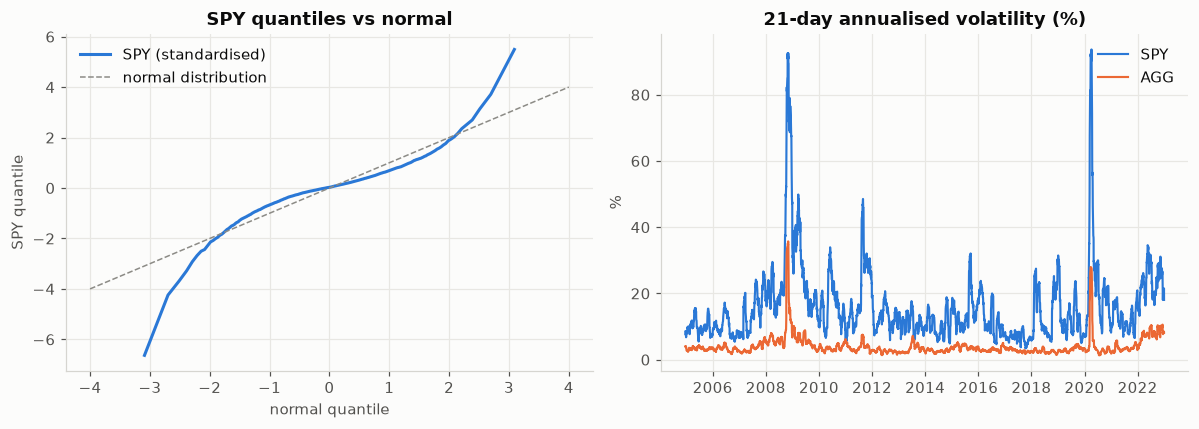

In [10]:
from scipy import stats as st
spy = lr["SPY"].dropna()
z = (spy - spy.mean()) / spy.std()
q = np.linspace(0.001, 0.999, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(st.norm.ppf(q), np.quantile(z, q), color=BLUE, label="SPY (standardised)")
axes[0].plot([-4, 4], [-4, 4], color=GREY, linewidth=1, linestyle="--", label="normal distribution")
axes[0].set(title="SPY quantiles vs normal", xlabel="normal quantile", ylabel="SPY quantile")
axes[0].legend(loc="upper left")
vol = lr[["SPY", "AGG"]].rolling(21).std() * np.sqrt(252) * 100
axes[1].plot(vol.index, vol["SPY"], color=BLUE, linewidth=1.4, label="SPY")
axes[1].plot(vol.index, vol["AGG"], color=ORANGE, linewidth=1.4, label="AGG")
axes[1].set(title="21-day annualised volatility (%)", ylabel="%")
axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

In [11]:
rows = []
for t in TICKERS:
    x = lr[t].dropna()
    rows.append({"ETF": t, "skew": x.skew(), "excess kurtosis": x.kurt(),
                 "ADF p (returns)": adfuller(x, autolag="AIC")[1],
                 "KPSS p (returns)": kpss(x, regression="c", nlags="auto")[1],
                 "ADF p (log price)": adfuller(np.log(adj[t].dropna()), autolag="AIC")[1],
                 "autocorr of r²": (x**2).autocorr(1)})
pd.DataFrame(rows)

,ETF,skew,excess kurtosis,ADF p (returns),KPSS p (returns),ADF p (log price),autocorr of r²
0,SPY,-0.3679,14.1849,2.4590e-29,0.1000,0.9506,0.2763
1,EFA,-0.3618,13.1371,4.3839e-27,0.1000,0.3504,0.2585
2,EEM,0.0432,15.0445,3.5644e-27,0.1000,0.0355,0.2195
3,AGG,-2.6709,71.6866,1.0607e-21,0.0444,0.2713,0.3142
4,GLD,-0.3151,6.1385,0.0000e+00,0.1000,0.2036,0.1160
5,XLE,-0.6950,12.7278,1.6728e-24,0.1000,0.1437,0.1842
6,XLK,-0.2349,10.3339,2.1517e-29,0.1000,0.9732,0.3703


In [12]:
# Formal tests behind the three stylised facts (H0 in brackets; small p = reject H0)
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
rows = []
for t in TICKERS:
    x = lr[t].dropna()
    rows.append({"ETF": t,
                 "Jarque-Bera p [normal]": jarque_bera(x)[1],
                 "Ljung-Box p, r, 10 lags [no autocorrelation]": acorr_ljungbox(x, lags=[10])["lb_pvalue"].iloc[0],
                 "Ljung-Box p, r², 10 lags [no vol. clustering]": acorr_ljungbox(x**2, lags=[10])["lb_pvalue"].iloc[0],
                 "ARCH-LM p, 10 lags [no ARCH effects]": het_arch(x - x.mean(), nlags=10)[1]})
pd.DataFrame(rows).set_index("ETF")

,Jarque-Bera p [normal],"Ljung-Box p, r, 10 lags [no autocorrelation]","Ljung-Box p, r², 10 lags [no vol. clustering]","ARCH-LM p, 10 lags [no ARCH effects]"
ETF,,,,
SPY,0.0,5.1996e-16,0.0000e+00,2.0311e-297
EFA,0.0,3.1827e-11,0.0000e+00,8.7463e-255
EEM,0.0,4.9080e-16,0.0000e+00,0.0000e+00
AGG,0.0,9.4971e-15,7.7395e-226,2.0637e-121
GLD,0.0,7.4681e-01,1.5758e-117,7.7742e-58
XLE,0.0,1.2553e-03,0.0000e+00,4.1320e-229
XLK,0.0,1.5727e-25,0.0000e+00,4.6278e-245


**Finding:** the formal tests confirm all three facts for every ETF: Jarque-Bera rejects normality (p ≈ 0), and Ljung-Box on squared returns and ARCH-LM reject "no volatility clustering" (p ≈ 0). Ljung-Box also finds small autocorrelation in the returns themselves for 6 of 7 ETFs (not GLD); with 4,500 observations even a tiny effect is "significant", and notebook 03 must check that it disappears after the GARCH filter. In the charts, the left tail is much fatter than normal (the curve bends away from the dashed line at the extremes), volatility comes in clusters (2008, 2020 and 2022 spikes; squared returns are autocorrelated), ADF rejects a unit root in every return series. Two borderline results need a sentence in the report: KPSS weakly rejects stationarity for AGG returns (p ≈ 0.04, consistent with its crisis jumps and volatility regimes), and ADF rejects a unit root in EEM's log price at 5% (p ≈ 0.04) while the other prices behave as random walks.
**Decision:** a plain normal VaR will understate the tail; models that let volatility change (GARCH-filtered historical simulation, conditional EVT) are justified. Model on returns, never on price levels. (KPSS p-values are capped at 0.1 by the table; values near the bound mean "no evidence against stationarity".)

## 8 · Does the bond hedge hold? It depends on the regime

The portfolio relies on AGG to cushion equity losses. Our research proposed that the hedge fails when **inflation** is high. We test that, plus two alternatives: the liquidity crises (2008 Q4, 2020 Q1) and **rate-hiking cycles** (the 3-month T-bill up by more than 1 pp over 12 months, known at t−1). CPI for month m is published around the middle of month m+1, so it is only used from then. Neither flag looks ahead.

In [13]:
cpi = pd.read_parquet(RAW / "fred_CPIAUCSL.parquet").iloc[:, -1]
cpi.index = pd.to_datetime(cpi.index)
yoy = cpi.pct_change(12)
yoy.index = yoy.index + pd.offsets.MonthBegin(1) + pd.Timedelta(days=14)      # usable from the 15th of month m+1
infl = yoy.reindex(lr.index, method="ffill") > 0.03
crisis = ((lr.index >= "2008-10-01") & (lr.index <= "2008-12-31")) | ((lr.index >= "2020-01-01") & (lr.index <= "2020-03-31"))
tbill = pd.read_parquet(RAW / "fred_DTB3.parquet").iloc[:, -1]
tbill.index = pd.to_datetime(tbill.index)
tbill = tbill.reindex(lr.index, method="ffill").shift(1)
hike = lambda pp: ((tbill - tbill.shift(252)) > pp).to_numpy()
regimes = {"normal (no crisis, no hiking)": ~crisis & ~hike(1.0), "liquidity crisis": crisis,
           "inflation > 3% (no crisis)": ~crisis & infl.to_numpy(), "rate hiking, 1 pp (no crisis)": ~crisis & hike(1.0),
           "rate hiking, 0.5 pp (sensitivity)": ~crisis & hike(0.5), "rate hiking, 1.5 pp (sensitivity)": ~crisis & hike(1.5)}

def corr_row(mask):
    d = lr.loc[mask, ["SPY", "AGG"]]
    w = d.resample("W-FRI").sum()
    w = w[(w != 0).all(axis=1)]
    return {"days": len(d), "daily Pearson": d.SPY.corr(d.AGG), "daily Spearman": d.SPY.corr(d.AGG, method="spearman"),
            "weekly Pearson": w.SPY.corr(w.AGG)}
pd.DataFrame({k: corr_row(m) for k, m in regimes.items()}).T

,days,daily Pearson,daily Spearman,weekly Pearson
"normal (no crisis, no hiking)",3907.0,-0.1836,-0.2186,-0.1645
liquidity crisis,126.0,0.1300,-0.1309,0.7011
inflation > 3% (no crisis),1259.0,-0.0395,-0.1093,0.0566
"rate hiking, 1 pp (no crisis)",527.0,0.3003,0.2103,0.3432
"rate hiking, 0.5 pp (sensitivity)",1031.0,0.1843,0.0611,0.2490
"rate hiking, 1.5 pp (sensitivity)",323.0,0.3722,0.2844,0.3750


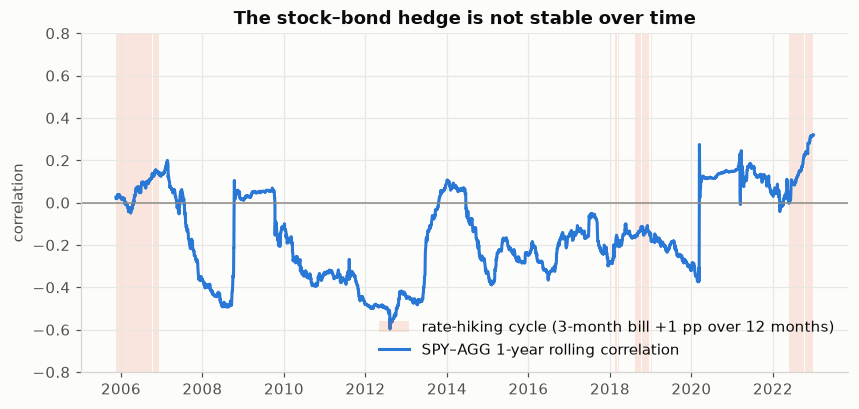

In [14]:
roll = lr["SPY"].rolling(252).corr(lr["AGG"])
fig, ax = plt.subplots()
ax.fill_between(roll.index, -0.8, 0.8, where=pd.Series(hike(1.0), index=lr.index).reindex(roll.index).to_numpy(),
                color=ORANGE, alpha=0.15, linewidth=0, label="rate-hiking cycle (3-month bill +1 pp over 12 months)")
ax.plot(roll.index, roll, color=BLUE, label="SPY–AGG 1-year rolling correlation")
ax.axhline(0, color=GREY, linewidth=1)
ax.set(ylim=(-0.8, 0.8), title="The stock–bond hedge is not stable over time", ylabel="correlation")
ax.legend(loc="lower right")
plt.show()

**Finding (descriptive):** the data **rejected our own hypothesis**. With lagged CPI above 3% the correlation is roughly zero, not positive: the 2008 and 2011 inflation spikes coincided with a strongly negative correlation (bonds rallied as a safe haven). What the positive periods (2005–06, 2018, 2022) share is **rising policy rates**. In rate-hiking cycles the correlation is about +0.3 (daily and weekly, Pearson and Spearman agree), against about −0.2 otherwise. The effect grows as the definition tightens (daily Pearson +0.18 at 0.5 pp, +0.30 at 1 pp, +0.37 at 1.5 pp), a dose-response pattern that supports it; at 0.5 pp the rank correlation is only +0.06, so a loose definition dilutes it. Read the numbers from the table, not the chart: the 1-year rolling line mixes regimes inside each window, so it lags (it stays negative through the short 2018 cycle), and 2020–21 is positive with no hiking cycle at all (the COVID shock and recovery). Rate hiking is the strongest single explanation we found, not the only one. In the liquidity crises the weekly correlation is high but rests on about 26 weeks, and the daily rank correlation stays negative, so a few extreme days drive it.
**Caveat:** the rate-hiking definition was found by looking at this chart on dev + validation data. It is exploratory evidence, not a tested model.
**Decision:** fix the regime definition (rate hiking, 1 pp) in the input lock **before** Phase 3 uses it, then use it for the stagflation scenario's correlation flip and the regime-conditioned risk work (gap G8). The memo must say AGG hedges equity losses in normal times and in deflationary crashes, **not** when policy rates are rising. Whether the flag is on at the decision date is computed only after the freeze.

### 8b · Hypothesis test: does hiking change the hedge once the other explanations are controlled for?

A table of correlations is not a test. We regress AGG's return on SPY's return with an **interaction** for each regime, all in one model so they compete (a "horse race"):

AGG_t = a + b·SPY_t + c_hike·(SPY_t × hike_t) + c_infl·(SPY_t × infl_t) + c_crisis·(SPY_t × crisis_t) + c_vix·(SPY_t × highVIX_t) + regime dummies + e_t

A positive c means AGG moves **with** stocks in that regime (the hedge weakens). Returns cluster and have fat tails, so plain OLS standard errors are wrong: we use **Newey-West (HAC)** errors. **Pre-stated hypotheses:** H1: c_hike > 0. H2: c_infl > 0 (our original research claim).

In [15]:
import statsmodels.api as sm
vix = pd.read_parquet(RAW / "fred_VIXCLS.parquet").iloc[:, -1]
vix.index = pd.to_datetime(vix.index)
vix = vix.reindex(lr.index, method="ffill").shift(1)
dgs2 = pd.read_parquet(RAW / "fred_DGS2.parquet").iloc[:, -1]
dgs2.index = pd.to_datetime(dgs2.index)
dgs2 = dgs2.reindex(lr.index, method="ffill").shift(1)
F = pd.DataFrame({"hike": hike(1.0), "infl": infl.to_numpy(), "crisis": crisis,
                  "high_vix": (vix > vix.rolling(1260, min_periods=252).median() * 1.5).to_numpy(),
                  "hike_2y": ((dgs2 - dgs2.shift(252)) > 1.0).to_numpy()}, index=lr.index)

def horse_race(y, x, flags, lags):
    X = pd.DataFrame({"SPY": x})
    for k in flags:
        X[f"SPY x {k}"] = x * flags[k].astype(float)
        X[k] = flags[k].astype(float)
    m = sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    keep = [c for c in m.params.index if c.startswith("SPY")]
    return m, pd.DataFrame({"coef": m.params[keep], "HAC s.e.": m.bse[keep], "p-value": m.pvalues[keep]})

d = lr[["SPY", "AGG"]].dropna()
m_daily, t_daily = horse_race(d.AGG, d.SPY, F.loc[d.index, ["hike", "infl", "crisis", "high_vix"]], 5)
wk = d.resample("W-FRI").sum()
Fw = F.astype(float).resample("W-FRI").mean().reindex(wk.index) > 0.5
m_week, t_week = horse_race(wk.AGG, wk.SPY, Fw[["hike", "infl", "crisis", "high_vix"]], 4)
_, t_2y = horse_race(d.AGG, d.SPY, F.loc[d.index, ["hike_2y", "infl", "crisis", "high_vix"]], 5)
pd.concat({"daily": t_daily, "weekly": t_week, "daily, hiking from 2-year yield": t_2y}, axis=1).round(4)

daily                   weekly                  daily, hiking from 2-year yield                 
                  coef HAC s.e. p-value    coef HAC s.e. p-value                            coef HAC s.e. p-value
SPY            -0.0491   0.0096  0.0000 -0.0653   0.0195  0.0008                         -0.0499   0.0093  0.0000
SPY x hike      0.1409   0.0273  0.0000  0.1054   0.0356  0.0030                             NaN      NaN     NaN
SPY x infl     -0.0052   0.0224  0.8150  0.0498   0.0476  0.2950                         -0.0126   0.0230  0.5848
SPY x crisis    0.0767   0.0332  0.0207  0.2667   0.0692  0.0001                          0.0826   0.0330  0.0123
SPY x high_vix  0.0155   0.0115  0.1788  0.0258   0.0236  0.2744                          0.0149   0.0116  0.1986
SPY x hike_2y      NaN      NaN     NaN     NaN      NaN     NaN                          0.1319   0.0250  0.0000

**Finding:** H1 is supported and H2 is rejected. Holding the other regimes fixed, the hiking interaction is +0.14 (HAC s.e. 0.027, p < 0.001) on daily data and +0.11 (p = 0.003) weekly, and the same with hiking defined from the 2-year yield (+0.13, p < 0.001). The inflation interaction is indistinguishable from zero (p = 0.30–0.82). In plain terms: normally AGG gains about 0.05% for each 1% fall in SPY; during a hiking cycle it **loses** about 0.09%. Liquidity crises also weaken the hedge (daily p = 0.02, weekly p < 0.001); high VIX on its own does not.

### 8c · How big is the difference, with honest uncertainty?

Block bootstrap (blocks of 20 trading days keep the time-series structure; regime labels move with the blocks): the 95% interval for corr(in regime) − corr(outside regime), crises excluded.

In [16]:
rng = np.random.default_rng(20261028)

def boot_diff(a, b, mask, block=20, reps=2000):
    A, B, M = a.to_numpy(), b.to_numpy(), np.asarray(mask)
    n = len(A)
    point = np.corrcoef(A[M], B[M])[0, 1] - np.corrcoef(A[~M], B[~M])[0, 1]
    out = []
    for _ in range(reps):
        idx = (rng.integers(0, n - block, n // block + 1)[:, None] + np.arange(block)).ravel()[:n]
        m, x, y = M[idx], A[idx], B[idx]
        out.append(np.corrcoef(x[m], y[m])[0, 1] - np.corrcoef(x[~m], y[~m])[0, 1])
    lo, hi = np.quantile(out, [0.025, 0.975])
    return {"difference": point, "95% CI low": lo, "95% CI high": hi, "share of resamples <= 0": np.mean(np.array(out) <= 0)}

nc = ~F.loc[d.index, "crisis"].to_numpy()
pd.DataFrame({"rate hiking vs not": boot_diff(d.SPY[nc], d.AGG[nc], F.loc[d.index, "hike"].to_numpy()[nc]),
              "CPI > 3% vs not": boot_diff(d.SPY[nc], d.AGG[nc], F.loc[d.index, "infl"].to_numpy()[nc])}).T.round(3)

,difference,95% CI low,95% CI high,share of resamples <= 0
rate hiking vs not,0.484,0.297,0.625,0.000
CPI > 3% vs not,0.115,-0.040,0.263,0.067


**Finding:** in hiking cycles the correlation is higher by +0.48 (95% CI +0.30 to +0.63; no resample at or below zero). For CPI above 3% the difference is +0.12 with a CI that includes zero (−0.04 to +0.26). The hiking effect is large and its interval is far from zero; the inflation effect is not distinguishable from noise.

### 8d · Residual and robustness checks: is the model believable?

1. **Residuals:** if the daily regression left strong autocorrelation or volatility clustering in its errors, ordinary p-values would be misleading. That is why we use HAC errors; this cell shows how much they were needed.
2. **Outliers:** do a few crisis days drive the result? Rank (Spearman) correlations, which ignore the size of extreme moves, answer that.

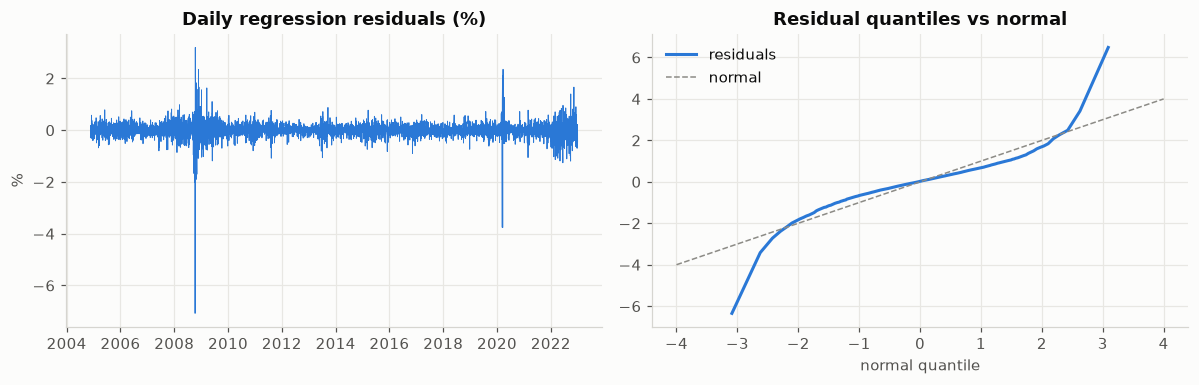

,"Ljung-Box p, residuals (10 lags)","Ljung-Box p, squared residuals (10 lags)",Spearman: hiking,Spearman: CPI > 3%,Spearman: neither
0,0.0,0.0,0.2103,-0.1093,-0.1971


In [17]:
resid = m_daily.resid
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(resid.index, resid * 100, color=BLUE, linewidth=0.6)
axes[0].set(title="Daily regression residuals (%)", ylabel="%")
z = (resid - resid.mean()) / resid.std()
qq = np.linspace(0.001, 0.999, 300)
axes[1].plot(st.norm.ppf(qq), np.quantile(z, qq), color=BLUE, label="residuals")
axes[1].plot([-4, 4], [-4, 4], color=GREY, linewidth=1, linestyle="--", label="normal")
axes[1].set(title="Residual quantiles vs normal", xlabel="normal quantile")
axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()
spearman = {k: lr.loc[F[k].to_numpy() & ~F["crisis"].to_numpy(), ["SPY", "AGG"]].corr(method="spearman").iloc[0, 1]
            for k in ["hike", "infl"]}
spearman["neither"] = lr.loc[~F["hike"].to_numpy() & ~F["infl"].to_numpy() & ~F["crisis"].to_numpy(),
                             ["SPY", "AGG"]].corr(method="spearman").iloc[0, 1]
pd.DataFrame({"Ljung-Box p, residuals (10 lags)": [acorr_ljungbox(resid, lags=[10])["lb_pvalue"].iloc[0]],
              "Ljung-Box p, squared residuals (10 lags)": [acorr_ljungbox(resid**2, lags=[10])["lb_pvalue"].iloc[0]],
              "Spearman: hiking": [spearman["hike"]], "Spearman: CPI > 3%": [spearman["infl"]],
              "Spearman: neither": [spearman["neither"]]}).round(4)

**Finding:** the residuals are strongly autocorrelated and clustered (both Ljung-Box p ≈ 0) and fat-tailed (right chart), so ordinary OLS p-values would be wrong: the HAC errors were necessary, not cosmetic. A conditional-correlation model (for example DCC-GARCH) would model this directly, but it is beyond what the decision needs. The rank correlations show the result is not driven by a few extreme days: Spearman is +0.21 in hiking cycles against −0.20 when neither regime is on, while CPI > 3% (−0.11) looks like normal times.

### 8e · Out of sample: does it hold on data the idea never saw?

The hiking definition was chosen after looking at 2004–2022, so in-sample p-values are optimistic. The honest test is **1990 to 2004-10**, which we have not looked at: the S&P 500 price index (`ext_GSPC`, validation-only file) against a Treasury bond proxy built from the 10-year yield (return ≈ −7 × yield change). Definitions are **fixed in advance**; nothing is re-tuned. AGG did not exist before 2003, so we first check the proxy on 2004–2022.

In [18]:
spx = pd.read_parquet(RAW / "ext_GSPC.parquet").iloc[:, 0]
spx.index = pd.to_datetime(spx.index)
y10 = pd.read_parquet(RAW / "fred_DGS10.parquet").iloc[:, -1]
y10.index = pd.to_datetime(y10.index)
proxy_in = -7.0 * y10.reindex(lr.index, method="ffill").diff() / 100
print(f"proxy check 2004-22: corr(AGG, proxy) = {lr.AGG.corr(proxy_in):.2f}; "
      f"corr(SPY, AGG) = {lr.SPY.corr(lr.AGG):+.3f}; corr(SPY, proxy) = {lr.SPY.corr(proxy_in):+.3f}")

o = pd.DataFrame({"equity": np.log(spx).diff(), "bond": -7.0 * y10.reindex(spx.index, method="ffill").diff() / 100}).dropna()
o = o.loc["1990-01-01":]
tb_o = tbill_full = pd.read_parquet(RAW / "fred_DTB3.parquet").iloc[:, -1]
tb_o.index = pd.to_datetime(tb_o.index)
tb_o = tb_o.reindex(o.index, method="ffill").shift(1)
hike_o = ((tb_o - tb_o.shift(252)) > 1.0).to_numpy()
infl_o = (yoy.reindex(o.index, method="ffill") > 0.03).to_numpy()
_, t_oos = horse_race(o.bond, o.equity, pd.DataFrame({"hike": hike_o, "infl": infl_o}, index=o.index), 5)
summary_oos = pd.DataFrame({
    "corr in regime": [o[hike_o].corr().iloc[0, 1], o[infl_o].corr().iloc[0, 1]],
    "corr outside": [o[~hike_o].corr().iloc[0, 1], o[~infl_o].corr().iloc[0, 1]],
    "days in regime": [int(hike_o.sum()), int(infl_o.sum())]}, index=["rate hiking", "CPI > 3%"])
boot_oos = pd.DataFrame({"rate hiking": boot_diff(o.equity, o.bond, hike_o), "CPI > 3%": boot_diff(o.equity, o.bond, infl_o)}).T
display(summary_oos.round(3), t_oos.round(4), boot_oos.round(3))

proxy check 2004-22: corr(AGG, proxy) = 0.71; corr(SPY, AGG) = -0.028; corr(SPY, proxy) = -0.324


,corr in regime,corr outside,days in regime
rate hiking,0.139,-0.005,553
CPI > 3%,0.094,-0.024,1339


,coef,HAC s.e.,p-value
SPY,-0.0130,0.0149,0.3845
SPY x hike,0.0484,0.0365,0.1843
SPY x infl,0.0367,0.0263,0.1626


,difference,95% CI low,95% CI high,share of resamples <= 0
rate hiking,0.145,-0.046,0.334,0.076
CPI > 3%,0.117,-0.057,0.278,0.094


**Finding:** the bond proxy tracks AGG well (correlation 0.71), but pure Treasuries hedge better than AGG (correlation with stocks −0.32 against −0.03), because AGG also holds corporate and mortgage bonds. Out of sample, the hiking effect has the **same sign** (+0.14 against −0.01) but is **not significant** (regression p = 0.18; bootstrap CI −0.05 to +0.33, with 92% of resamples above zero). The test **cannot separate** hiking from inflation in 1990–2004: CPI > 3% shows a similar weak effect (+0.12, CI −0.06 to +0.28), because the two overlapped then (1990, 2000) and there are only two hiking cycles (1994–95, 1999–2000).

### 8f · Evidence verdict: how much can we claim?

| Claim | Visual | In-sample test | Robustness | Out of sample | Status |
|---|---|---|---|---|---|
| Returns are fat-tailed and volatility clusters | §7 charts | Jarque-Bera, Ljung-Box r², ARCH-LM: p ≈ 0 for all 7 ETFs | Holds for every ETF | Textbook fact (not re-tested) | **Strong** |
| The hedge weakens in **rate-hiking cycles** | §8 chart | +0.14, p < 0.001 (daily); p = 0.003 (weekly); CI of the difference +0.30 to +0.63 | Spearman agrees; 2-year-yield definition agrees; effect grows as the definition tightens; HAC errors handle residual clustering | Same sign, not significant (p = 0.18); only 2 cycles | **Moderate:** supported in-sample, directional out of sample, definition chosen after looking |
| The hedge fails when **CPI > 3%** (our original claim) | §8 table | ≈ 0, p = 0.30–0.82; CI includes zero | Spearman looks like normal times | Weak same-sign effect, not significant, confounded with hiking | **Not supported:** do not claim |
| The hedge weakens in **liquidity crises** | §6 chart | p = 0.02 (daily), p < 0.001 (weekly) | Daily Spearman stays negative: a few extreme days drive it | Not tested | **Plausible:** use as a stress scenario, not as a model input |

**Decisions connected to this evidence:**
1. Pre-register in the input lock: the regime definition (3-month bill up > 1 pp over 12 months), hypothesis H1 and the wording below. Nothing is re-tuned after that.
2. Stagflation scenario (notebook 05): use the hiking-regime correlation (about +0.3) as the stressed SPY–AGG correlation, against about −0.2 in normal times.
3. Liquidity crises enter as the "liquidity day" stress (§6), not as a model regime.
4. Risk models must allow changing volatility (strong evidence): GARCH-filtered models are justified; notebook 03 checks the GARCH residuals.
5. Memo wording: "In normal times and in crashes, our bond holding offsets part of an equity loss. When the central bank is raising rates, it has historically moved with stocks instead. The evidence for this is moderate: strong in 2004–2022, the same direction but not statistically significant in 1990–2004."

## 9 · Reconciliation: does the pipeline see the same data?

The last check compares our independently computed returns with the pipeline's saved artifact. This is the only place the pipeline's output is read.

In [19]:
art = pd.read_parquet(ART / "returns_simple.parquet").loc[:END, TICKERS]
mine = r_adj.reindex(art.index)
print("max absolute difference:", float((mine - art).abs().max().max()))

max absolute difference: 0.0


**Finding:** the pipeline's returns equal our independent recomputation (difference at machine precision).
**Decision:** the data layer is signed off once the owner has re-run this notebook and rewritten the findings above in their own words.

## Summary for the report

| # | Question | Finding | Decision |
|---|---|---|---|
| 0 | Snapshot unchanged? | All hashes match | Use as is |
| 1 | Complete? | No gaps, duplicates or bad prices; starts 2004-11-18 | Limitation: no 2000–02 crash |
| 2 | Adjustment right? | Matches close + dividends | Adjusted close for all returns |
| 3 | Matches reality? | Annual returns match published figures | Returns trusted |
| 4 | Stale prices? | None | No extra flag |
| 5 | Extremes explained? | Oct 2008, Mar 2020 events | Keep all (flag, don't delete) |
| 6 | AGG fat tails? | ETF discount crashes, not bond moves | Liquidity-day stress + limitation (G7) |
| 7 | Stylised facts? | Fat tails, clustering, stationary returns (all formally tested, p ≈ 0) | Volatility-aware models justified |
| 8 | Bond hedge? | Weakens in rate-hiking cycles (moderate evidence: p < 0.001 in-sample, same sign out of sample); CPI > 3% not supported | Pre-register H1; stressed correlation +0.3 in the stagflation scenario (G8) |
| 9 | Pipeline agrees? | Identical | Data layer signed off after owner review |